<p align="center">
  <img src="assets/hero_kavram.svg" width="100%" alt="Gün 55 — K-Means'e giriş: benzer olan bir araya">
</p>

<p align="center">
  <img src="https://img.shields.io/badge/G%C3%BCn-55-1B1446?style=for-the-badge" alt="Gün 55">
  <img src="https://img.shields.io/badge/Konu-K--Means_(Kavram)-FBBF24?style=for-the-badge" alt="Konu">
  <img src="https://img.shields.io/badge/Seviye-Ba%C5%9Flang%C4%B1%C3%A7-16A34A?style=for-the-badge" alt="Seviye">
  <img src="https://img.shields.io/badge/Veri-M%C3%BC%C5%9Fteri_Ki%C5%9Fili%C4%9Fi_(Kaggle)-38BDF8?style=for-the-badge" alt="Veri">
  <img src="https://img.shields.io/badge/Animasyon-5_GIF-F472B6?style=for-the-badge" alt="Animasyon">
</p>

<table>
<tr><td width="25%" valign="top" align="center"><h3>🏷️</h3><b>Etiket yok</b><br><br>Kimse "bu müşteri şu gruptandır"<br>demiyor; <b>veri kendisi</b> buluyor<br><br></td><td width="25%" valign="top" align="center"><h3>🧲</h3><b>Çekim merkezleri</b><br><br>Her grup bir <b>yıldızın</b><br>etrafında toplanıyor<br><br></td><td width="25%" valign="top" align="center"><h3>🔁</h3><b>Ata ve taşı</b><br><br>İki basit adım, <b>durulana</b><br>kadar tekrar<br><br></td><td width="25%" valign="top" align="center"><h3>🛒</h3><b>Gerçek müşteriler</b><br><br>Bir market zincirinin<br><b>2 bin müşterisi</b> üzerinde<br><br></td></tr>
</table>

<table><tr><td>

<img src="assets/etiket_hedef.svg" height="34" alt="Hedefler">

**Bu notebook'un sonunda şunları yapabiliyor olacaksınız:**

- 🏷️ **Gözetimli** ve **gözetimsiz** öğrenme arasındaki farkı bir cümleyle anlatmak
- 🧲 K-Means'i **"yıldızlar ve çekim alanları"** benzetmesiyle, formüle boğulmadan açıklamak
- 📏 İki müşteri arasındaki **mesafeyi** (Öklid ve Manhattan) hesaplamak
- ✍️ 8 müşteriyle **elle K-Means** yapıp `scikit-learn` ile birebir aynı sonucu almak
- ➗ **Ölçekleme** yapılmazsa neden tek bir özelliğin her şeyi belirlediğini görmek
- 🎲 **Rastgele başlangıç tuzağını** ve **K-Means++** çözümünü deneyle ölçmek
- 🦵 **Kaç küme?** sorusuna dirsek, diz noktası ve **üç kalite ölçütüyle** cevap aramak
- 🌙 K-Means'in **sevmediği şekilleri** tanımak ve yeni gelen müşteriyi doğru şekilde **gruba atamak**

Teknik ayrıntı bilinçli olarak az tutuldu; her kavramın yanında **bir resim, bir animasyon ve bir deney** var.

</td></tr></table>

<p align="center">
  <img src="assets/yol_haritasi_kavram.svg" width="100%" alt="Kavram yol haritası: 12 durak">
</p>

### 🧭 Hızlı Erişim

| Durak | Bölüm | Ana soru |
|:-:|:--|:--|
| 🧰 1 | [Kurulum](#p1) | Hangi araçlarla çalışıyoruz? |
| 🏷️ 2 | [Etiketsiz dünya](#p2) | Cevap anahtarı yoksa ne öğrenilir? |
| 🧲 3 | [K-Means fikri](#p3) | Yıldızlar nasıl yerini bulur? |
| 📏 4 | [Mesafe](#p4) | "Benzer" ne demek, nasıl ölçülür? |
| ✍️ 5 | [Elle K-Means](#p5) | 8 müşteriyle adım adım nasıl hesaplanır? |
| ➗ 6 | [Ölçekleme](#p6) | Büyük sayılı özellik neden her şeyi ele geçirir? |
| 🎲 7 | [Başlangıç tuzağı](#p7) | Kötü başlangıç neden kötü gruplar verir? |
| 🦵 8 | [Kaç küme?](#p8) | Dirsek nerede? |
| 📐 9 | [Kalite ölçütleri](#p9) | Silüet, Davies-Bouldin, Calinski-Harabasz ne söyler? |
| 🌙 10 | [Sınırlar](#p10) | K-Means nerede yanılır? |
| 🆕 11 | [Yeni müşteri](#p11) | Eğitimden sonra gelen müşteri hangi gruba girer? |
| 🎓 12 | [Özet](#p12) | Akılda kalanlar, quiz, ödevler, kaynakça |

<a id="p1"></a>

<p align="center">
  <img src="assets/kavram_01.svg" width="100%" alt="Bölüm 1: Kurulum">
</p>

Kütüphaneleri ve çizim yardımcılarını tek hücrede topluyoruz. Animasyonlar `outputs/figures` klasörüne **GIF** olarak kaydedilir ve notebook içinde oynatılır. Tüm rastgelelik `RANDOM_STATE = 42` ile sabitlenir.

In [1]:
# ── Kütüphaneler ─────────────────────────────────────────────
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import Image, Markdown, display
from matplotlib.animation import FuncAnimation, PillowWriter
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score
from sklearn.datasets import make_blobs, make_moons, make_circles

from musteri_yardimci import veri_oku, ozellik_uret, KUME_OZELLIKLERI, LOG_SUTUNLARI

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
FIG_DIR = Path("outputs/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)
REP_DIR = Path("outputs/reports"); REP_DIR.mkdir(parents=True, exist_ok=True)

# Renk paleti (gece moru + yıldız renkleri); küme renkleri sabit sırayla kullanılır
RENK = {"altin": "#E5A100", "mavi": "#2B6CB0", "pembe": "#D1495B", "yesil": "#2E9E6B", "mor": "#6C5CE7",
        "turuncu": "#E8833A", "cyan": "#0E9AA7", "gri": "#8A94A6", "koyu": "#1F2A44"}
KUME_RENK = ["#E5A100", "#2B6CB0", "#D1495B", "#2E9E6B", "#6C5CE7", "#E8833A", "#0E9AA7", "#8D6E63", "#5C6BC0", "#AD1457"]
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight", "axes.titleweight": "bold",
                     "axes.titlesize": 13, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False, "grid.alpha": 0.25})


def kaydet(fig, ad):
    """Grafiği outputs/figures altına PNG olarak kaydeder."""
    fig.savefig(FIG_DIR / f"{ad}.png")
    print(f"💾 Kaydedildi → outputs/figures/{ad}.png")


def gif_kaydet(kare_ciz, n_kare, ad, figsize=(8, 4.6), fps=3):
    """kare_ciz(i, fig) fonksiyonuyla animasyon üretir, GIF olarak kaydeder ve notebook'ta gösterir."""
    fig = plt.figure(figsize=figsize)
    def guncelle(i):
        fig.clear(); kare_ciz(i, fig)
        return []
    anim = FuncAnimation(fig, guncelle, frames=n_kare, blit=False)
    yol = FIG_DIR / f"{ad}.gif"
    anim.save(yol, writer=PillowWriter(fps=fps), dpi=80)
    plt.close(fig)
    print(f"🎞️ Animasyon → {yol}")
    display(Image(filename=str(yol)))


def rapor_kaydet(df, ad, index=True):
    """Tabloyu outputs/reports altına CSV olarak yazar."""
    df.to_csv(REP_DIR / f"{ad}.csv", index=index, encoding="utf-8-sig")
    print(f"📄 Rapor → outputs/reports/{ad}.csv")


def bolge_ciz(ax, model, Z, adim=0.02, alfa=0.12):
    """Modelin her noktayı hangi yıldıza 'çektiğini' arka planda renkli bölgeler olarak çizer (Voronoi)."""
    x0, x1 = Z[:, 0].min() - .5, Z[:, 0].max() + .5; y0, y1 = Z[:, 1].min() - .5, Z[:, 1].max() + .5
    xx, yy = np.meshgrid(np.arange(x0, x1, adim), np.arange(y0, y1, adim))
    lab = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, lab, levels=np.arange(lab.max() + 2) - .5, colors=KUME_RENK[:lab.max() + 1], alpha=alfa)

print("scikit-learn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.1 | numpy 2.5.3 | pandas 3.0.5


<a id="p2"></a>

<p align="center">
  <img src="assets/kavram_02.svg" width="100%" alt="Bölüm 2: Etiketsiz dünya">
</p>


### 🏷️ 2.1 · Öğretmenli ve Öğretmensiz Öğrenme

Şimdiye kadar gördüğümüz algoritmaların (karar ağacı, XGBoost, LightGBM…) hepsinin bir **cevap anahtarı** vardı: "bu yolcu kurtuldu", "bu fasulye Bombay". Buna **gözetimli (supervised)** öğrenme denir.

Bugün cevap anahtarı **yok**. Elimizde yalnızca müşteriler ve davranışları var; "bu müşteri şu gruptandır" diyen bir sütun bulunmuyor. Amaç, **birbirine benzeyenleri bir araya toplamak**: buna **kümeleme (clustering)** ve bu tür öğrenmeye **gözetimsiz (unsupervised)** öğrenme denir.

<p align="center">
  <img src="assets/diyagram_gozetimsiz.svg" width="100%" alt="Gözetimli ve gözetimsiz öğrenme">
</p>

### 🛒 2.2 · Bu Derste Kullanacağımız Veri: Bir Market Zincirinin Müşterileri

**Kaggle "Customer Personality Analysis"** verisi: bir gıda/market zincirinin 2.240 müşterisinin geliri, aile yapısı ve **son iki yılda** hangi üründen ne kadar harcadığı, hangi kanaldan (web, katalog, mağaza) kaç kez alışveriş yaptığı. Yardımcı dosyamız (`musteri_yardimci.py`) bu ham sütunlardan anlaşılır Türkçe özellikler üretir: **Gelir, Yaş, Çocuk, Toplam harcama, Alışveriş sayısı, İndirim oranı, Web ziyaret/ay**.

Bu derste veriyi yalnızca **en bariz hatalardan** temizliyoruz (130 yaşında müşteri, 666.666 gelir, tekrarlanan satırlar, eksik gelir); ayrıntılı temizlik ve karar defteri proje notebook'unda.

In [2]:
ham = veri_oku()
print("Ham veri (satır, sütun):", ham.shape)

# En bariz hatalar: doğum yılı < 1920 (≥ 94 yaş), gelir > 200 bin (tek bir 666.666 kaydı), eksik gelir, tekrar eden satırlar
ozellik_disi = [c for c in ham.columns if c != "ID"]
temiz = (ham[(ham["Year_Birth"] >= 1920) & ~(ham["Income"] > 200_000)]
         .dropna(subset=["Income"])
         .drop_duplicates(subset=ozellik_disi))
F = ozellik_uret(temiz).reset_index(drop=True)
print("Temizlenmiş müşteri sayısı:", len(F))
display(F[KUME_OZELLIKLERI].head(6).round(2))

Ham veri (satır, sütun): (2240, 29)
Temizlenmiş müşteri sayısı: 2030


,Gelir,Yaş,Çocuk,Toplam harcama,Alışveriş sayısı,İndirim oranı,Web ziyaret/ay
0,58138.0,57,0,1617,22,0.12,7
1,46344.0,60,2,27,4,0.33,5
2,71613.0,49,0,776,20,0.05,4
3,26646.0,30,1,53,6,0.25,6
4,58293.0,33,1,422,14,0.26,5
5,62513.0,47,1,716,20,0.09,6


<table><tr><td>

<img src="assets/etiket_ipucu.svg" height="34" alt="İpucu">

**Etiket sütunu yok.** Tabloda "segment" diye bir sütun göremezsiniz; K-Means'in işi bu sütunu **kendisi üretmek**. Bu yüzden "doğruluk" (accuracy) gibi bir skor hesaplayamayız; kaliteyi başka yollarla ölçeceğiz (9. durak).

</td></tr></table>

### 👀 2.3 · Gözünüzle Kaç Grup Görüyorsunuz?

Önce yalnızca iki özelliğe bakalım: **yıllık gelir** ve **iki yıllık toplam harcama**. Harcama çok çarpık olduğu için (birkaç müşteri çok fazla harcıyor) logaritmik eksende çiziyoruz.

💾 Kaydedildi → outputs/figures/kavram_01_etiketsiz_musteriler.png


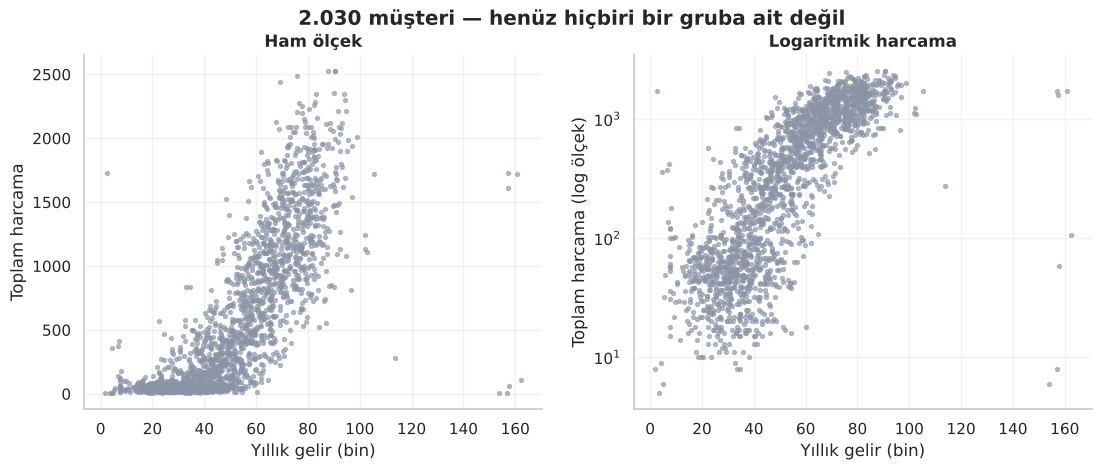

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
ax[0].scatter(F["Gelir"] / 1000, F["Toplam harcama"], s=8, color=RENK["gri"], alpha=.6)
ax[0].set(xlabel="Yıllık gelir (bin)", ylabel="Toplam harcama", title="Ham ölçek")
ax[1].scatter(F["Gelir"] / 1000, F["Toplam harcama"], s=8, color=RENK["gri"], alpha=.6)
ax[1].set_yscale("log"); ax[1].set(xlabel="Yıllık gelir (bin)", ylabel="Toplam harcama (log ölçek)", title="Logaritmik harcama")
fig.suptitle(f"{len(F):,} müşteri — henüz hiçbiri bir gruba ait değil".replace(",", "."), fontweight="bold")
kaydet(fig, "kavram_01_etiketsiz_musteriler"); plt.show()

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Gerçek müşteri verisinde, ders kitaplarındaki gibi **birbirinden kopuk adalar** yoktur; daha çok **birbirine karışan bulutlar** görürüz. Yine de sağdaki grafikte en az iki yoğunluk fark ediliyor: **az harcayan** geniş bir kitle ve **çok harcayan** varlıklı bir grup. K-Means, bu bulutu en mantıklı şekilde **dilimlemeye** çalışacak.

</td></tr></table>

<a id="p3"></a>

<p align="center">
  <img src="assets/kavram_03.svg" width="100%" alt="Bölüm 3: K-Means fikri">
</p>


### 🧲 3.1 · Yıldızlar ve Çekim Alanları

Gökyüzüne **k tane yıldız** (merkez, *centroid*) yerleştirdiğinizi düşünün. Her müşteri, **en yakın yıldızın** çekim alanına düşer. Sonra her yıldız, kendine bağlanan müşterilerin **tam ortasına** (ortalamasına) taşınır. Yıldız taşınınca bazı müşteriler artık başka bir yıldıza daha yakındır; onlar taraf değiştirir. **Kimse taraf değiştirmeyene kadar** bu iki adım tekrarlanır.

K-Means adı da buradan gelir: **k** tane **ortalama** (*means*).

<p align="center">
  <img src="assets/diyagram_kmeans_dongusu.svg" width="100%" alt="K-Means'in dört adımlık döngüsü">
</p>

Bu döngünün her turunda **WCSS** (grup içi kareler toplamı: her müşterinin kendi yıldızına uzaklığının karesi, hepsinin toplamı) **küçülür ya da aynı kalır**; asla artmaz. Bu yüzden algoritma mutlaka durur.

### 🎞️ 3.2 · Canlı K-Means (Animasyon)

Gelir ve (log) harcamayı standartlaştırıp 3 yıldızı **bilerek kötü** bir yerden başlatıyoruz. Her karede ya **atama** (müşteriler renk alır) ya da **taşıma** (yıldızlar ortalamaya gider) adımını görüyorsunuz. Arka plandaki renkli bölgeler, her yıldızın **çekim alanıdır**.

Algoritma 13 turda durdu. İlk 6 ve son 2 tur:


,WCSS (atamadan sonra),Yıldızların toplam kayması
Tur,,
1,16252.7,6.9232
2,1173.3,1.1319
3,961.1,0.1726
4,955.6,0.0804
5,953.9,0.0631
6,953.1,0.0429
12,952.1,0.0048
13,952.1,0.0000


📄 Rapor → outputs/reports/kavram_kmeans_turlari.csv


🎞️ Animasyon → outputs/figures/kavram_02_kmeans_canli.gif


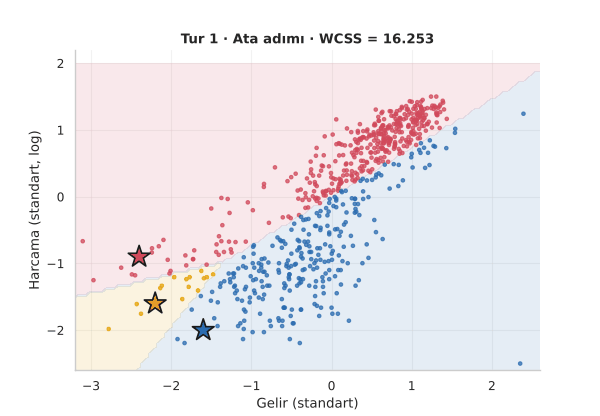

In [4]:
iki = np.c_[np.log(F["Gelir"]), np.log1p(F["Toplam harcama"])]
olcek2 = StandardScaler().fit(iki); Z2 = olcek2.transform(iki)
rng = np.random.default_rng(RANDOM_STATE)
alt = rng.choice(len(Z2), 700, replace=False)                 # çizim hızlı olsun diye 700 müşteri

# Bilerek kötü başlangıç: üç yıldız da sol alt köşeye yakın
C = np.array([[-2.2, -1.6], [-1.6, -2.0], [-2.4, -0.9]])
kareler, tur_kaydi = [], []
for tur in range(1, 101):
    etiket = ((Z2[:, None, :] - C[None]) ** 2).sum(-1).argmin(1)                 # ATA: en yakın yıldız
    wcss = ((Z2 - C[etiket]) ** 2).sum()
    kareler.append(("Ata", tur, C.copy(), etiket.copy(), wcss))
    yeni = np.array([Z2[etiket == j].mean(0) for j in range(3)])                  # TAŞI: grubun ortalaması
    tur_kaydi.append({"Tur": tur, "WCSS (atamadan sonra)": round(wcss, 1), "Yıldızların toplam kayması": round(np.abs(yeni - C).sum(), 4)})
    kareler.append(("Taşı", tur, yeni.copy(), etiket.copy(), ((Z2 - yeni[etiket]) ** 2).sum()))
    if np.abs(yeni - C).sum() < 1e-6: break                                     # kımıldamıyorsa dur
    C = yeni
tur_tablo = pd.DataFrame(tur_kaydi).set_index("Tur")
print(f"Algoritma {len(tur_tablo)} turda durdu. İlk 6 ve son 2 tur:"); display(pd.concat([tur_tablo.head(6), tur_tablo.tail(2)]))
rapor_kaydet(tur_tablo, "kavram_kmeans_turlari")

class _Sabit:                        # bolge_ciz() için en yakın yıldızı döndüren küçük yardımcı
    def __init__(self, C): self.C = C
    def predict(self, X): return ((X[:, None, :] - self.C[None]) ** 2).sum(-1).argmin(1)

def kare(i, fig):
    adim, tur, Cc, et, w = kareler[min(i, len(kareler) - 1)]
    ax = fig.add_subplot(1, 1, 1)
    bolge_ciz(ax, _Sabit(Cc), Z2, adim=.05)
    ax.scatter(Z2[alt, 0], Z2[alt, 1], s=10, c=[KUME_RENK[e] for e in et[alt]], alpha=.75)
    ax.scatter(Cc[:, 0], Cc[:, 1], s=420, marker="*", c=KUME_RENK[:3], edgecolor="k", linewidth=1.5, zorder=5)
    ax.set(xlabel="Gelir (standart)", ylabel="Harcama (standart, log)", xlim=(-3.2, 2.6), ylim=(-2.6, 2.2))
    ax.set_title(f"Tur {tur} · {adim} adımı · WCSS = {w:,.0f}".replace(",", "."))
secim = list(range(min(12, len(kareler)))) + [len(kareler) - 1] * 3                 # ilk 6 tur + son durum
kareler = [kareler[i] for i in secim]
gif_kaydet(kare, len(kareler), "kavram_02_kmeans_canli", figsize=(7.5, 5.2), fps=2)

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Yıldızlar sol alt köşeden başladı; ilk turda neredeyse herkes **tek bir yıldıza** bağlandı. Ama her taşıma adımında yıldızlar bulutun içine doğru yürüdü ve **ilk 3 turda** büyük ölçüde yerine oturdu; sonraki turlar yalnızca sınırdaki birkaç müşteriyi el değiştirtti. Tablodaki WCSS sütunu her turda **azalıyor**, yıldızların kayması **sıfıra** iniyor: işte durma koşulu. Ayrıca bu iki boyutlu (gelir × log harcama) görünümde gerçekten **üç yoğunluk** seçilebiliyor: düşük gelirli küçük bir grup, orta kesim ve yüksek gelirli çok harcayanlar.

</td></tr></table>

<a id="p4"></a>

<p align="center">
  <img src="assets/kavram_04.svg" width="100%" alt="Bölüm 4: Mesafe">
</p>


### 📏 4.1 · "Benzer" Ne Demek?

K-Means için iki müşteri ne kadar **yakınsa** o kadar **benzer**dir. Yakınlığı ölçmenin iki yaygın yolu var:

<p align="center">
  <img src="assets/diyagram_mesafe.svg" width="100%" alt="Öklid ve Manhattan mesafesi">
</p>

Gerçek iki müşteriyi alıp (gelir ve log harcama, standart birimde) iki mesafeyi de hesaplayalım:

In [5]:
ayse, mehmet = 10, 25                                         # veriden iki gerçek müşteri (satır numarası)
ikili = pd.DataFrame(Z2[[ayse, mehmet]], index=["Ayşe", "Mehmet"], columns=["Gelir (std)", "Harcama (std)"]).round(3)
ikili["Gerçek gelir"] = F.loc[[ayse, mehmet], "Gelir"].values
ikili["Gerçek harcama"] = F.loc[[ayse, mehmet], "Toplam harcama"].values
display(ikili)

fark = Z2[ayse] - Z2[mehmet]
oklid = np.sqrt((fark ** 2).sum())
manhattan = np.abs(fark).sum()
print(f"Öklid (kuş uçuşu)     : √({fark[0]:.3f}² + {fark[1]:.3f}²) = {oklid:.3f}")
print(f"Manhattan (sokak sokak): |{fark[0]:.3f}| + |{fark[1]:.3f}|   = {manhattan:.3f}")

,Gelir (std),Harcama (std),Gerçek gelir,Gerçek harcama
Ayşe,-3.616,-1.018,7500.0,61
Mehmet,0.260,-0.049,53359.0,257


Öklid (kuş uçuşu)     : √(-3.876² + -0.969²) = 3.995
Manhattan (sokak sokak): |-3.876| + |-0.969|   = 4.845


<table><tr><td>

<img src="assets/etiket_not.svg" height="34" alt="Not">

Manhattan mesafesi her zaman Öklid'den **büyük ya da eşittir** (köşeden dönmek kuş uçuşundan kısa olamaz). Klasik K-Means **Öklid** kullanır; çünkü "ortalama" (merkez) tam olarak Öklid kareler toplamını en küçük yapan noktadır. Manhattan kullanmak isterseniz merkez **medyan** olur: bu kardeş algoritmanın adı **K-Medyan**dır (proje notebook'unda yarışacak).

</td></tr></table>

<a id="p5"></a>

<p align="center">
  <img src="assets/kavram_05.svg" width="100%" alt="Bölüm 5: Elle K-Means">
</p>


### ✍️ 5.1 · 8 Müşteri, 2 Grup, Kalem Kâğıt

Algoritmanın sihir olmadığını görmek için **8 gerçek müşteriyle** elle K-Means yapalım (k = 2). Başlangıç yıldızları olarak **A** ve **B** müşterilerini seçiyoruz.

In [6]:
sekiz_idx = np.random.default_rng(7).choice(len(F), 8, replace=False)
S = pd.DataFrame(Z2[sekiz_idx], columns=["Gelir", "Harcama"], index=list("ABCDEFGH")).round(2)
display(S.assign(**{"Gerçek gelir": F.loc[sekiz_idx, "Gelir"].values, "Gerçek harcama": F.loc[sekiz_idx, "Toplam harcama"].values}))

merkez = S.loc[["A", "B"]].to_numpy()                     # Adım 1 · Tohum: A ve B
for tur in range(1, 6):
    uz = np.sqrt(((S.to_numpy()[:, None, :] - merkez[None]) ** 2).sum(-1))          # Adım 2 · her müşterinin iki yıldıza uzaklığı
    grup = uz.argmin(1)
    tablo = pd.DataFrame({"Yıldız 1'e uzaklık": uz[:, 0].round(2), "Yıldız 2'ye uzaklık": uz[:, 1].round(2),
                          "Grup": np.where(grup == 0, "1", "2")}, index=S.index)
    yeni = np.array([S.to_numpy()[grup == j].mean(0) for j in range(2)])           # Adım 3 · ortalamaya taşı
    display(Markdown(f"**Tur {tur}** · yıldızlar: 1 = ({merkez[0, 0]:.2f}, {merkez[0, 1]:.2f}), 2 = ({merkez[1, 0]:.2f}, {merkez[1, 1]:.2f})"))
    display(tablo.T)
    if np.allclose(yeni, merkez):
        display(Markdown(f"✅ **Tur {tur}'te kimse grup değiştirmedi → algoritma durdu.**")); break
    merkez = yeni
elle_grup, elle_merkez = grup, merkez

,Gelir,Harcama,Gerçek gelir,Gerçek harcama
A,-3.10,-0.67,9722.0,103
B,0.67,0.24,65735.0,395
C,-0.74,0.05,32233.0,296
D,0.19,0.24,51373.0,393
E,-1.18,-1.72,25707.0,21
F,-0.33,0.05,39660.0,299
G,1.05,1.20,79419.0,1631
H,0.96,1.09,76068.0,1376


**Tur 1** · yıldızlar: 1 = (-3.10, -0.67), 2 = (0.67, 0.24)

,A,B,C,D,E,F,G,H
Yıldız 1'e uzaklık,0.0,3.88,2.47,3.41,2.19,2.86,4.55,4.43
Yıldız 2'ye uzaklık,3.88,0.0,1.42,0.48,2.7,1.02,1.03,0.9
Grup,1,2,2,2,1,2,2,2


**Tur 2** · yıldızlar: 1 = (-2.14, -1.20), 2 = (0.30, 0.48)

,A,B,C,D,E,F,G,H
Yıldız 1'e uzaklık,1.09,3.16,1.87,2.74,1.09,2.2,3.99,3.85
Yıldız 2'ye uzaklık,3.59,0.44,1.12,0.26,2.65,0.76,1.04,0.9
Grup,1,2,2,2,1,2,2,2


✅ **Tur 2'te kimse grup değiştirmedi → algoritma durdu.**

**Doğrulama:** Aynı başlangıçla `scikit-learn`'ün `KMeans` sınıfını çalıştırıp sonuçları karşılaştıralım.

Elle bulunan gruplar      : [0 1 1 1 0 1 1 1]
scikit-learn'ün grupları  : [0 1 1 1 0 1 1 1]
Merkezler arası en büyük fark: 0.0
💾 Kaydedildi → outputs/figures/kavram_03_elle_kmeans.png


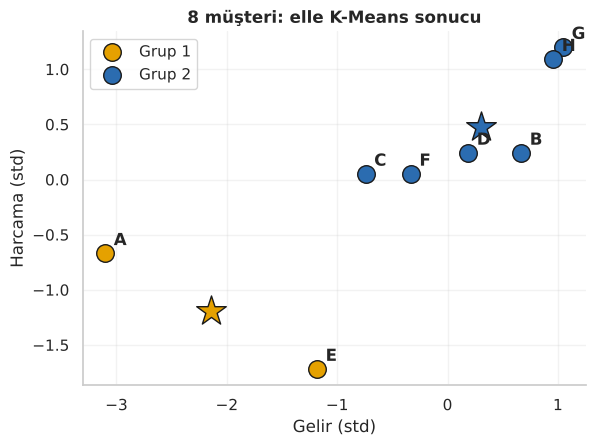

In [7]:
km8 = KMeans(n_clusters=2, init=S.loc[["A", "B"]].to_numpy(), n_init=1).fit(S.to_numpy())
print("Elle bulunan gruplar      :", elle_grup)
print("scikit-learn'ün grupları  :", km8.labels_)
print("Merkezler arası en büyük fark:", np.abs(np.sort(elle_merkez, 0) - np.sort(km8.cluster_centers_, 0)).max().round(12))

fig, ax = plt.subplots(figsize=(6.5, 4.6))
for j in range(2):
    m = elle_grup == j
    ax.scatter(S.iloc[m, 0], S.iloc[m, 1], s=160, color=KUME_RENK[j], edgecolor="k", label=f"Grup {j + 1}")
    ax.scatter(*elle_merkez[j], s=500, marker="*", color=KUME_RENK[j], edgecolor="k")
for ad, (x, y) in S.iterrows(): ax.annotate(ad, (x, y), xytext=(6, 6), textcoords="offset points", fontweight="bold")
ax.set(xlabel="Gelir (std)", ylabel="Harcama (std)", title="8 müşteri: elle K-Means sonucu"); ax.legend()
kaydet(fig, "kavram_03_elle_kmeans"); plt.show()

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Elle yaptığımız hesap ile `scikit-learn` **aynı grupları ve aynı merkezleri** buldu. K-Means'in bütün "zekâsı" iki satırdır: **en yakına ata, ortalamaya taşı**. Gerçek veride tek fark, bunun binlerce müşteri ve onlarca tur için bilgisayarda yapılmasıdır.

</td></tr></table>

<a id="p6"></a>

<p align="center">
  <img src="assets/kavram_06.svg" width="100%" alt="Bölüm 6: Ölçekleme">
</p>


### ➗ 6.1 · Büyük Sayılar Haksız Üstünlük Kurar

Gelir **on binlerle**, çocuk sayısı **0–3** arasında ölçülür. Mesafe hesaplarken 10.000 birimlik gelir farkı, 3 çocuk farkını **yutar**. Sonuç: K-Means yalnızca gelire bakar, çocukları **görmez**.

<p align="center">
  <img src="assets/diyagram_olcekleme.svg" width="100%" alt="Ölçeklemeden önce ve sonra">
</p>

Deneyelim: aynı iki özellikle (gelir, çocuk sayısı) **ölçeklemeden** ve **standartlaştırarak** K-Means (k = 3) kuralım. Her özelliğin grupları ne kadar ayırdığını **η² (eta kare)** ile ölçeceğiz: özelliğin yayılımının **gruplar arasındaki farktan** gelen payı (0 = hiç ayırmıyor, 1 = tamamen ayırıyor).

,Ölçeksiz,Standartlaştırılmış
Gelir η²,0.818,0.629
Çocuk η²,0.207,0.696


📄 Rapor → outputs/reports/kavram_olcekleme.csv


**Okuma:** ölçeksiz modelde gelir η² = **0.82**, çocuk η² = **0.21**; standartlaştırınca çocuk η² **0.70**'ye çıkıyor.

💾 Kaydedildi → outputs/figures/kavram_04_olcekleme.png


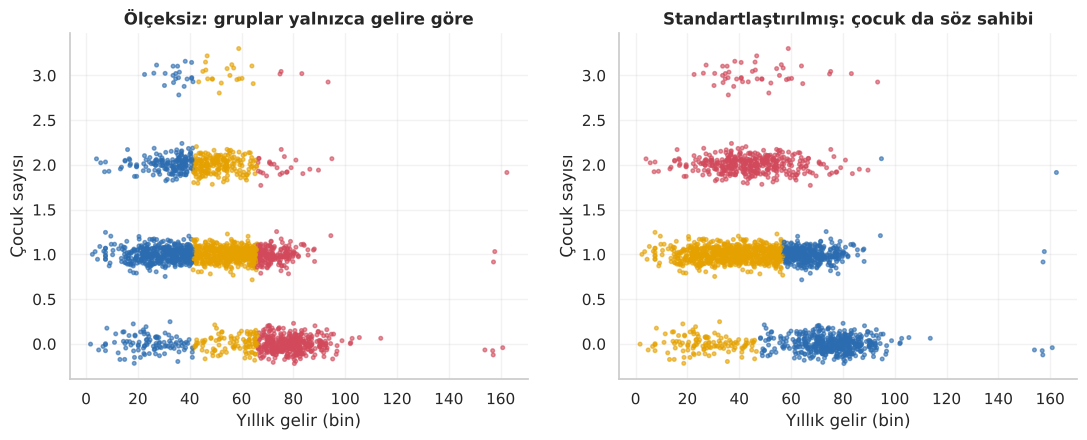

In [8]:
GC = F[["Gelir", "Çocuk"]].to_numpy(dtype=float)
def eta_kare(x, et):
    """Bir özelliğin toplam yayılımının gruplar arası farktan gelen payı."""
    genel = x.mean(); ara = sum((et == j).sum() * (x[et == j].mean() - genel) ** 2 for j in np.unique(et))
    return ara / ((x - genel) ** 2).sum()

et_ham = KMeans(3, n_init=10, random_state=RANDOM_STATE).fit_predict(GC)
et_std = KMeans(3, n_init=10, random_state=RANDOM_STATE).fit_predict(StandardScaler().fit_transform(GC))
olcek_tablo = pd.DataFrame({"Ölçeksiz": [eta_kare(GC[:, 0], et_ham), eta_kare(GC[:, 1], et_ham)],
                            "Standartlaştırılmış": [eta_kare(GC[:, 0], et_std), eta_kare(GC[:, 1], et_std)]},
                           index=["Gelir η²", "Çocuk η²"]).round(3)
display(olcek_tablo); rapor_kaydet(olcek_tablo, "kavram_olcekleme")
display(Markdown(f"**Okuma:** ölçeksiz modelde gelir η² = **{olcek_tablo.iloc[0, 0]:.2f}**, çocuk η² = **{olcek_tablo.iloc[1, 0]:.2f}**; standartlaştırınca çocuk η² **{olcek_tablo.iloc[1, 1]:.2f}**'ye çıkıyor."))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
titre = np.random.default_rng(1).normal(0, .08, len(GC))          # aynı çocuk sayısındaki noktalar üst üste binmesin
for a, et, b in [(ax[0], et_ham, "Ölçeksiz: gruplar yalnızca gelire göre"), (ax[1], et_std, "Standartlaştırılmış: çocuk da söz sahibi")]:
    a.scatter(GC[:, 0] / 1000, GC[:, 1] + titre, s=7, c=[KUME_RENK[e] for e in et], alpha=.6)
    a.set(xlabel="Yıllık gelir (bin)", ylabel="Çocuk sayısı", title=b)
kaydet(fig, "kavram_04_olcekleme"); plt.show()

<table><tr><td>

<img src="assets/etiket_dikkat.svg" height="34" alt="Dikkat">

Ölçeksiz modelde gruplar **dikey şeritler** hâlinde: sınırları yalnızca gelir çiziyor. Çocuk sayısının η²'si sıfır değil; ama bunun nedeni K-Means'in çocuğa bakması değil, **düşük gelirli müşterilerin daha çok çocuklu olması** (iki özellik birbiriyle ilişkili). Standartlaştırınca çocuk sayısı **kendi başına** grupları ayırmaya başladı. **Mesafeye dayanan her algoritmadan önce** (K-Means, KNN, SVM…) özellikleri aynı ölçeğe getirmek neredeyse her zaman şarttır. `StandardScaler` (ortalama 0, yayılım 1) ya da `MinMaxScaler` (0–1 arası) kullanılabilir; **hangisinin daha iyi olduğu veriye göre değişir** ve denenerek seçilir.

</td></tr></table>

<a id="p7"></a>

<p align="center">
  <img src="assets/kavram_07.svg" width="100%" alt="Bölüm 7: Başlangıç tuzağı">
</p>


### 🎲 7.1 · Kötü Başlangıç, Kötü Gruplar

K-Means **bulduğu ilk vadiye** iner: başlangıç yıldızları kötü yere düşerse (örneğin ikisi aynı grubun içine), algoritma oradan çıkamayabilir ve iki gerçek grubu **birleştirip** bir başkasını **ikiye böler**. Buna **rastgele başlangıç tuzağı** denir.

**Çözüm 1 · K-Means++:** ilk yıldız rastgele seçilir; sonraki her yıldız, mevcut yıldızlara **uzak** müşterilerden (uzaklığın karesiyle orantılı olasılıkla) seçilir. Böylece yıldızlar en baştan **dağınık** başlar.

**Çözüm 2 · Birden çok deneme (`n_init`):** algoritmayı farklı başlangıçlarla birkaç kez çalıştırıp **WCSS'i en küçük** olanı tutmak.

<p align="center">
  <img src="assets/diyagram_kpp.svg" width="100%" alt="Başlangıç tuzağı ve K-Means++">
</p>

### 🧪 7.2 · Deney: 200 Farklı Başlangıç

Her başlangıç yöntemiyle K-Means'i **200 kez tek denemeyle** (`n_init=1`) çalıştırıp WCSS dağılımına bakıyoruz. İki veriyle deniyoruz:

1. **Gerçek müşteriler** (7 özellik, k = 5)
2. **Yapay (sentetik) 8 adalı veri** *(gerçek değildir; tuzağı açıkça göstermek için üretildi)*

ortalama   en_kotu  \
Veri                    Başlangıç                       
Gerçek müşteriler (k=5) K-Means++     1.802    10.149   
                        Rastgele      1.962    10.180   
Sentetik 8 ada (k=8)    K-Means++     6.608    12.845   
                        Rastgele    236.613  1118.868   

                                   %1'den kötü deneme oranı  
Veri                    Başlangıç                            
Gerçek müşteriler (k=5) K-Means++                     0.440  
                        Rastgele                      0.450  
Sentetik 8 ada (k=8)    K-Means++                     0.590  
                        Rastgele                      0.935

📄 Rapor → outputs/reports/kavram_baslangic_tuzagi.csv


**Okuma:** sentetik veride en iyi çözümden ortalama sapma rastgele başlangıçta **%237**, K-Means++ ile **%6.6**; gerçek müşterilerde ise **%2.0** ve **%1.8**.

💾 Kaydedildi → outputs/figures/kavram_05_baslangic_tuzagi.png


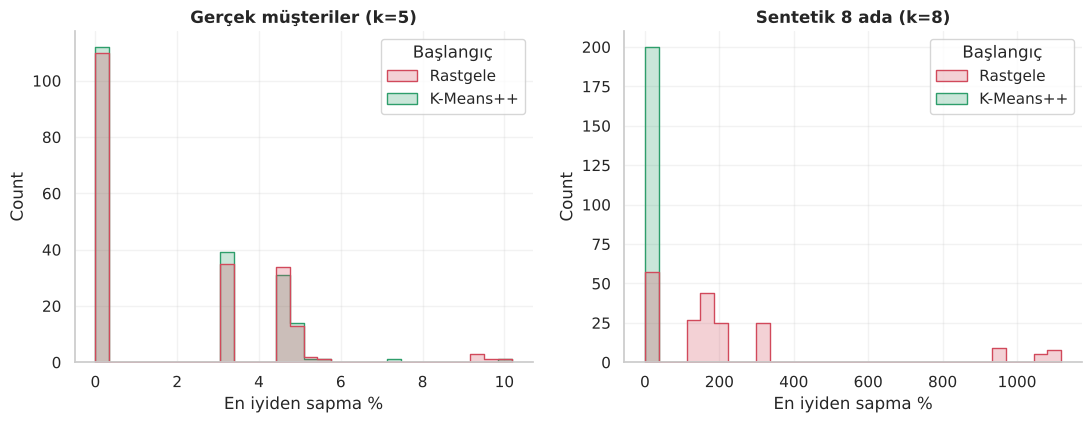

In [9]:
X7 = F[KUME_OZELLIKLERI].copy()
X7[LOG_SUTUNLARI] = np.log1p(X7[LOG_SUTUNLARI])                # çarpık sütunları log ile sıkıştır
Z7 = StandardScaler().fit_transform(X7)
Xs, ys = make_blobs(n_samples=800, centers=8, cluster_std=0.6, center_box=(-9, 9), random_state=11)

deney = []
for veri_ad, V, k in [("Gerçek müşteriler (k=5)", Z7, 5), ("Sentetik 8 ada (k=8)", Xs, 8)]:
    for yontem in ["random", "k-means++"]:
        for tohum in range(200):
            w = KMeans(k, init=yontem, n_init=1, random_state=tohum).fit(V).inertia_
            deney.append({"Veri": veri_ad, "Başlangıç": "Rastgele" if yontem == "random" else "K-Means++", "WCSS": w})
deney = pd.DataFrame(deney)
en_iyi = deney.groupby("Veri")["WCSS"].transform("min")
deney["En iyiden sapma %"] = (deney["WCSS"] / en_iyi - 1) * 100
ozet = deney.groupby(["Veri", "Başlangıç"])["En iyiden sapma %"].agg(
    ortalama="mean", en_kotu="max", **{"%1'den kötü deneme oranı": lambda s: (s > 1).mean()}).round(3)
display(ozet); rapor_kaydet(ozet, "kavram_baslangic_tuzagi")
o = ozet["ortalama"]
display(Markdown(f"**Okuma:** sentetik veride en iyi çözümden ortalama sapma rastgele başlangıçta **%{o.loc[('Sentetik 8 ada (k=8)', 'Rastgele')]:.0f}**, K-Means++ ile **%{o.loc[('Sentetik 8 ada (k=8)', 'K-Means++')]:.1f}**; gerçek müşterilerde ise **%{o.loc[('Gerçek müşteriler (k=5)', 'Rastgele')]:.1f}** ve **%{o.loc[('Gerçek müşteriler (k=5)', 'K-Means++')]:.1f}**."))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
for a, (v, g) in zip(ax, deney.groupby("Veri")):
    sns.histplot(data=g, x="En iyiden sapma %", hue="Başlangıç", bins=30, ax=a, palette=[RENK["pembe"], RENK["yesil"]], element="step")
    a.set_title(v)
kaydet(fig, "kavram_05_baslangic_tuzagi"); plt.show()

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

**Sentetik 8 adalı veride** rastgele başlangıç çoğu denemede iki adayı birleştirip birini bölüyor; WCSS en iyinin **katlarına** çıkabiliyor. K-Means++ bu felaketleri neredeyse tamamen önlüyor; ama tek denemede yine de çoğu zaman **en iyiyi tam yakalayamıyor**. İşte bu yüzden ikinci sigorta, **birden çok deneme (`n_init`)** gerekir. **Gerçek müşteri verisinde** iki yöntem arasındaki fark çok küçük: net adalar olmadığı için felaket yaratacak "yanlış vadi" yok. Ders: **K-Means++ + birkaç deneme** ucuz bir sigortadır; `scikit-learn`'de varsayılan olarak zaten açıktır.

</td></tr></table>

### 🎞️ 7.3 · K-Means++ Yıldızlarını Nasıl Seçer? (Animasyon)

Sentetik 8 adalı veride, her karede **yeni bir yıldız** seçiliyor. Noktaların büyüklüğü, o noktanın **bir sonraki yıldız olma olasılığıyla** orantılı: mevcut yıldızlara uzak noktalar büyür.

🎞️ Animasyon → outputs/figures/kavram_06_kmeanspp_tohumlama.gif


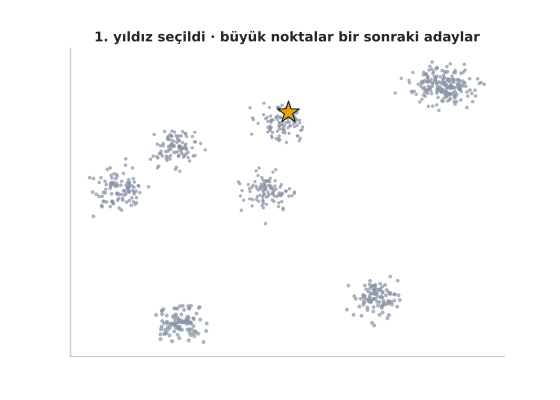

In [10]:
rng = np.random.default_rng(3)
secilen = [Xs[rng.integers(len(Xs))]]
olas_kayit = []
for _ in range(7):
    d2 = ((Xs[:, None, :] - np.array(secilen)[None]) ** 2).sum(-1).min(1)
    p = d2 / d2.sum(); olas_kayit.append(p)
    secilen.append(Xs[rng.choice(len(Xs), p=p)])
secilen = np.array(secilen)

def kare(i, fig):
    ax = fig.add_subplot(1, 1, 1); j = min(i, 7)
    boy = 6 if j == 7 else 4 + 900 * olas_kayit[j]
    ax.scatter(Xs[:, 0], Xs[:, 1], s=boy, color=RENK["gri"], alpha=.6)
    ax.scatter(secilen[:j + 1, 0], secilen[:j + 1, 1], s=420, marker="*", c=KUME_RENK[:j + 1], edgecolor="k", zorder=5)
    ax.set_title(f"{j + 1}. yıldız seçildi" + (" · büyük noktalar bir sonraki adaylar" if j < 7 else " · hepsi farklı adalarda"))
    ax.set_xticks([]); ax.set_yticks([])
gif_kaydet(kare, 10, "kavram_06_kmeanspp_tohumlama", figsize=(7, 5), fps=1)

<a id="p8"></a>

<p align="center">
  <img src="assets/kavram_08.svg" width="100%" alt="Bölüm 8: Kaç küme?">
</p>


### 🦵 8.1 · Dirsek Yöntemi

K-Means'in en büyük zayıflığı: **k'yı bizim vermemiz** gerekir. En bilinen yol **dirsek (elbow) yöntemi**dir: k = 1, 2, 3… için WCSS'i hesaplayıp çizeriz. Grup ekledikçe WCSS hep düşer (k = müşteri sayısı olursa sıfır olur!) ama bir noktadan sonra düşüş **yavaşlar**. Eğrinin **kolun dirseği** gibi büküldüğü yer iyi bir adaydır.

<p align="center">
  <img src="assets/diyagram_dirsek.svg" width="100%" alt="Dirsek yöntemi">
</p>

Dirseği gözle bulmak öznel olabilir; **Kneedle** algoritması (`kneed` kütüphanesi) eğrinin **en çok büküldüğü** noktayı otomatik bulur. Gerçek müşterilerin 7 özelliğiyle deneyelim:

In [11]:
wcss = {k: KMeans(k, n_init=10, random_state=RANDOM_STATE).fit(Z7).inertia_ for k in range(1, 11)}
try:
    from kneed import KneeLocator
    diz = KneeLocator(list(wcss), list(wcss.values()), curve="convex", direction="decreasing").elbow
    print("kneed ile bulunan dirsek noktası: k =", diz)
except ImportError:                                            # kneed kurulu değilse aynı fikrin kısa bir sürümü
    k_ = np.array(list(wcss)); w_ = np.array(list(wcss.values()))
    xn = (k_ - k_.min()) / (k_.max() - k_.min()); yn = (w_ - w_.min()) / (w_.max() - w_.min())
    diz = int(k_[np.argmax((1 - xn) - yn)]); print("Kneedle (elle) dirsek noktası: k =", diz)

dirsek_tablo = pd.DataFrame({"WCSS": wcss}).assign(**{"Bir öncekine göre düşüş %": lambda t: (-t["WCSS"].pct_change() * 100).round(1)}).round(1)
dirsek_tablo.index.name = "k"; display(dirsek_tablo.T); rapor_kaydet(dirsek_tablo, "kavram_dirsek")

kneed ile bulunan dirsek noktası: k = 3


k,1,2,3,4,5,6,7,8,9,10
WCSS,14210.0,8168.1,6831.5,5908.8,5315.1,4945.7,4621.1,4332.9,4102.5,3880.9
Bir öncekine göre düşüş %,NaN,42.5,16.4,13.5,10.0,7.0,6.6,6.2,5.3,5.4


📄 Rapor → outputs/reports/kavram_dirsek.csv


### 🎞️ 8.2 · k Arttıkça Müşteri Haritası (Animasyon)

7 özellikli müşterileri ekranda görebilmek için 2 boyutlu bir **haritaya** (PCA, Gün 54) indiriyoruz. Solda k arttıkça haritanın nasıl bölündüğünü, sağda WCSS eğrisinin nasıl oluştuğunu izleyin.

🎞️ Animasyon → outputs/figures/kavram_07_dirsek_harita.gif


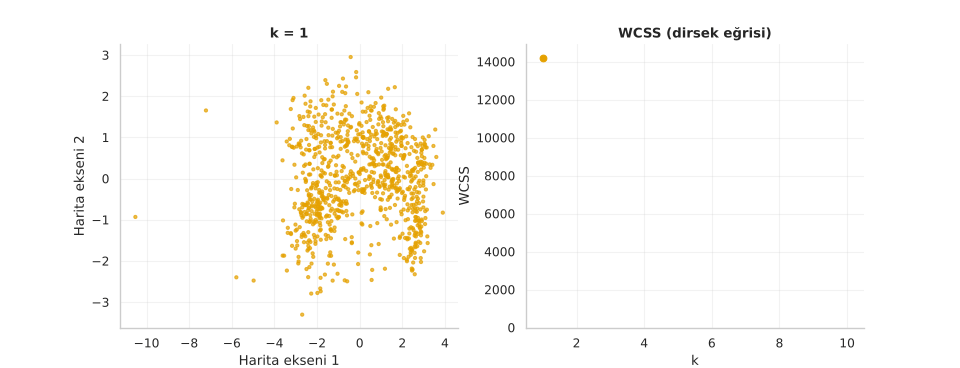

In [12]:
H = PCA(2, random_state=RANDOM_STATE).fit_transform(Z7)
alt = np.random.default_rng(RANDOM_STATE).choice(len(H), 900, replace=False)
etiketler = {k: KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(Z7) for k in range(1, 9)}

def kare(i, fig):
    k = min(i + 1, 8)
    a1 = fig.add_subplot(1, 2, 1); a2 = fig.add_subplot(1, 2, 2)
    a1.scatter(H[alt, 0], H[alt, 1], s=8, c=[KUME_RENK[e] for e in etiketler[k][alt]], alpha=.7)
    a1.set(title=f"k = {k}", xlabel="Harita ekseni 1", ylabel="Harita ekseni 2")
    ks = list(range(1, k + 1))
    a2.plot(ks, [wcss[x] for x in ks], "o-", color=RENK["altin"], lw=2.5); a2.set_xlim(.5, 10.5); a2.set_ylim(0, wcss[1] * 1.05)
    if k >= diz: a2.scatter([diz], [wcss[diz]], s=300, facecolor="none", edgecolor=RENK["pembe"], lw=3)
    a2.set(title="WCSS (dirsek eğrisi)", xlabel="k", ylabel="WCSS")
gif_kaydet(kare, 10, "kavram_07_dirsek_harita", figsize=(12, 4.6), fps=1)

<table><tr><td>

<img src="assets/etiket_not.svg" height="34" alt="Not">

Gerçek veride dirsek **her zaman keskin değildir**; eğri yumuşak bir yay gibi de inebilir. Bu yüzden dirsek tek başına karar vermez; bir **aday** verir. Kararı bir sonraki duraktaki kalite ölçütleri ve en önemlisi **iş anlamı** (bu gruplarla pazarlama ekibi ne yapacak?) birlikte verir.

</td></tr></table>

<a id="p9"></a>

<p align="center">
  <img src="assets/kavram_09.svg" width="100%" alt="Bölüm 9: Kalite ölçütleri">
</p>


### 📐 9.1 · Silüet: "Doğru Gruptayım" Hissi

Etiket olmadan kaliteyi ölçmek için grupların **sıkı** (içeride birbirine yakın) ve **ayrık** (dışarıdakilere uzak) olmasına bakarız. Her müşteri için:

<p align="center">
  <img src="assets/diyagram_siluet.svg" width="100%" alt="Silüet skoru">
</p>

Tek bir müşterinin silüetini elle hesaplayıp `scikit-learn` ile karşılaştıralım (k = 3):

In [13]:
et3 = etiketler[3]
i = 0                                                          # ilk müşteri
uz = np.sqrt(((Z7 - Z7[i]) ** 2).sum(1))
kendi = et3[i]
a_i = uz[(et3 == kendi) & (np.arange(len(Z7)) != i)].mean()                       # kendi grubuna ort. uzaklık
b_i = min(uz[et3 == j].mean() for j in np.unique(et3) if j != kendi)              # en yakın komşu gruba ort. uzaklık
s_i = (b_i - a_i) / max(a_i, b_i)
print(f"a(i) = {a_i:.4f}   b(i) = {b_i:.4f}   →   s(i) = {s_i:.4f}")
print(f"scikit-learn silhouette_samples      →   s(i) = {silhouette_samples(Z7, et3)[i]:.4f}")

a(i) = 2.6100   b(i) = 2.6481   →   s(i) = 0.0144
scikit-learn silhouette_samples      →   s(i) = 0.0144


### 📊 9.2 · Üç Ölçüt Birlikte

<p align="center">
  <img src="assets/diyagram_olcutler.svg" width="100%" alt="Üç kalite ölçütü">
</p>

Her k için üç ölçütü hesaplayalım. **Dikkat:** yönleri farklı! Silüet ve Calinski-Harabasz'da **büyük** iyidir, Davies-Bouldin'de **küçük**.

,Silüet ↑,Davies-Bouldin ↓,Calinski-Harabasz ↑
k,,,
2,0.373000,1.082000,1500.103000
3,0.268000,1.314000,1094.640000
4,0.256000,1.405000,948.760000
5,0.247000,1.299000,847.218000
6,0.237000,1.352000,758.274000
7,0.222000,1.450000,699.641000
8,0.243000,1.226000,658.467000
9,0.237000,1.410000,622.406000
10,0.226000,1.339000,597.365000


📄 Rapor → outputs/reports/kavram_kalite_olcutleri.csv
Her ölçütün en iyi bulduğu k: {'Silüet ↑': 2, 'Davies-Bouldin ↓': 2, 'Calinski-Harabasz ↑': 2}
💾 Kaydedildi → outputs/figures/kavram_08_uc_olcut.png


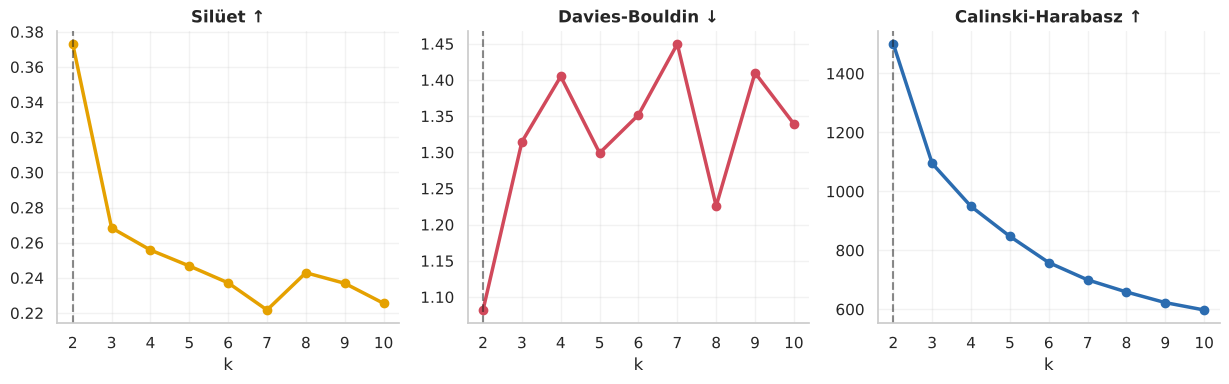

In [14]:
for k in range(9, 11): etiketler[k] = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(Z7)
olcut = pd.DataFrame({k: {"Silüet ↑": silhouette_score(Z7, etiketler[k]), "Davies-Bouldin ↓": davies_bouldin_score(Z7, etiketler[k]),
                          "Calinski-Harabasz ↑": calinski_harabasz_score(Z7, etiketler[k])} for k in range(2, 11)}).T
olcut.index.name = "k"
en_iyi = {"Silüet ↑": olcut["Silüet ↑"].idxmax(), "Davies-Bouldin ↓": olcut["Davies-Bouldin ↓"].idxmin(), "Calinski-Harabasz ↑": olcut["Calinski-Harabasz ↑"].idxmax()}
display(olcut.round(3).style.highlight_max(subset=["Silüet ↑", "Calinski-Harabasz ↑"], color="#C6F6D5").highlight_min(subset=["Davies-Bouldin ↓"], color="#C6F6D5"))
rapor_kaydet(olcut.round(4), "kavram_kalite_olcutleri")
print("Her ölçütün en iyi bulduğu k:", en_iyi)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, (s, r) in zip(ax, [("Silüet ↑", RENK["altin"]), ("Davies-Bouldin ↓", RENK["pembe"]), ("Calinski-Harabasz ↑", RENK["mavi"])]):
    a.plot(olcut.index, olcut[s], "o-", color=r, lw=2.5); a.axvline(en_iyi[s], color="k", ls="--", alpha=.5)
    a.set(title=s, xlabel="k"); a.set_xticks(olcut.index)
kaydet(fig, "kavram_08_uc_olcut"); plt.show()

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Üç ölçüt de en iyi skoru **k = 2**'de veriyor: müşteri verisindeki en güçlü ayrım **"çok harcayan / az harcayan"** ayrımıdır. Ama dikkat: bu ölçütler **geometrik** iyiliği ölçer, **iş için yararlılığı** değil. İki segment pazarlama ekibine pek yeni bir şey söylemez. Proje notebook'unda bu gerilimi **önceden yazılmış bir kuralla** (kararlılık + en küçük segment + ölçütler + iş kısıtı) çözeceğiz.

</td></tr></table>

### 🎞️ 9.3 · Silüet Bıçakları (Animasyon)

Her müşterinin silüet değerini, grubuna göre sıralayıp yatay çubuk olarak çizince **bıçak** şekilleri çıkar. Kalın ve uzun bıçaklar iyi gruplardır; **sola (negatife) taşan** çubuklar yanlış grupta olabilecek müşterilerdir. Kesikli çizgi ortalama silüettir.

🎞️ Animasyon → outputs/figures/kavram_09_siluet_bicaklari.gif


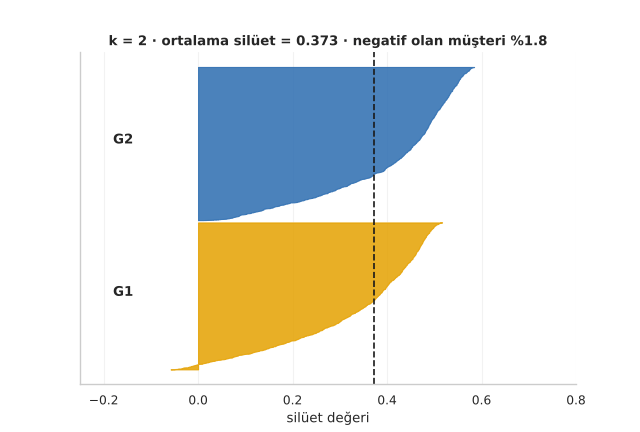

In [15]:
def kare(i, fig):
    k = min(i + 2, 7); et = etiketler[k]; s = silhouette_samples(Z7, et)
    ax = fig.add_subplot(1, 1, 1); y0 = 10
    for j in range(k):
        sj = np.sort(s[et == j])
        ax.fill_betweenx(np.arange(y0, y0 + len(sj)), 0, sj, color=KUME_RENK[j], alpha=.85)
        ax.text(-0.18, y0 + len(sj) / 2, f"G{j + 1}", fontweight="bold"); y0 += len(sj) + 15
    ax.axvline(s.mean(), color="k", ls="--"); ax.set_xlim(-.25, .8); ax.set_yticks([])
    ax.set(title=f"k = {k} · ortalama silüet = {s.mean():.3f} · negatif olan müşteri %{(s < 0).mean() * 100:.1f}", xlabel="silüet değeri")
gif_kaydet(kare, 7, "kavram_09_siluet_bicaklari", figsize=(8, 5.4), fps=1)

<a id="p10"></a>

<p align="center">
  <img src="assets/kavram_10.svg" width="100%" alt="Bölüm 10: Sınırlar">
</p>


### 🌙 10.1 · K-Means'in Sevmediği Şekiller

K-Means her grubu **yuvarlak** ve **benzer büyüklükte** varsayar (her nokta en yakın merkeze gider, sınırlar düz çizgidir). Bu varsayım bozulduğunda yanılır:

<p align="center">
  <img src="assets/diyagram_sekil_tuzaklari.svg" width="100%" alt="K-Means'in sevmediği şekiller">
</p>

Dört **yapay (sentetik)** veriyle gösterelim *(bu veriler gerçek değildir, kavramı göstermek için üretildi)*. Her birinde K-Means'i iki "kardeşle" karşılaştırıyoruz: **DBSCAN** (yoğunluğa bakar, şekil varsaymaz) ve **Gauss karışım modeli (GMM)** (her grubu eğik/basık bir elips sayabilir). Gerçek grupları bildiğimiz için başarıyı **ARI** (düzeltilmiş Rand indeksi: 1 = mükemmel eşleşme, 0 ≈ rastgele) ile ölçüyoruz.

💾 Kaydedildi → outputs/figures/kavram_10_sekil_tuzaklari.png


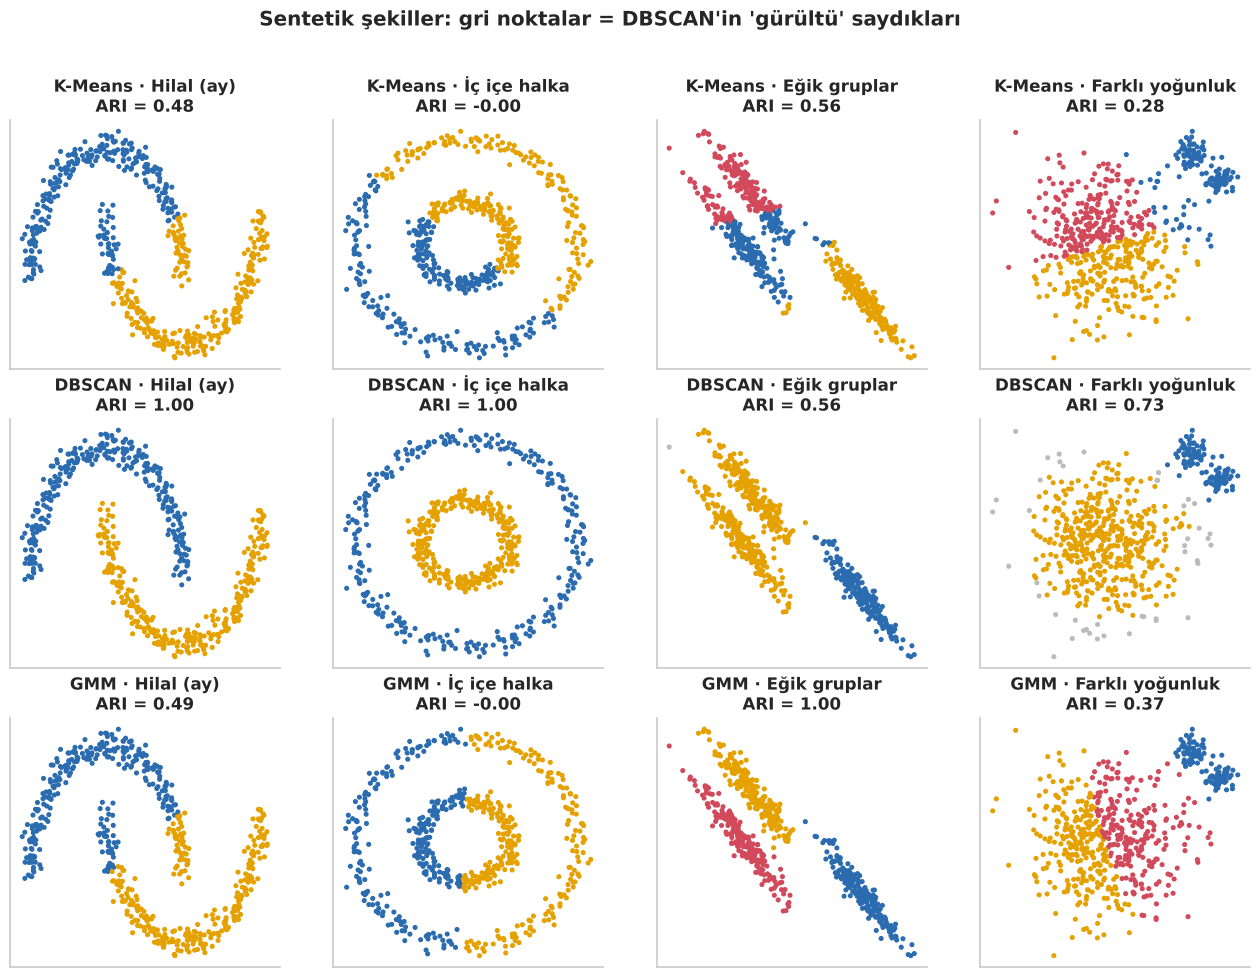

,DBSCAN,GMM,K-Means
Eğik gruplar,0.564,1.000,0.564
Farklı yoğunluk,0.727,0.371,0.281
Hilal (ay),1.000,0.494,0.480
İç içe halka,1.000,-0.001,-0.002


📄 Rapor → outputs/reports/kavram_sekil_ari.csv


In [16]:
from sklearn.metrics import adjusted_rand_score
rng = np.random.default_rng(0)
Xa, ya = make_blobs(600, centers=3, random_state=170); Xa = Xa @ np.array([[0.6, -0.64], [-0.41, 0.85]])  # eğik (basık) gruplar
Xd, yd = make_blobs(n_samples=[500, 60, 60], centers=[[0, 0], [5, 5], [6.5, 3.5]], cluster_std=[2.2, .4, .4], random_state=4)
setler = {"Hilal (ay)": make_moons(600, noise=.06, random_state=0), "İç içe halka": make_circles(600, factor=.4, noise=.05, random_state=0),
          "Eğik gruplar": (Xa, ya), "Farklı yoğunluk": (Xd, yd)}
algler = {"K-Means": lambda X, k: KMeans(k, n_init=10, random_state=0).fit_predict(X),
          "DBSCAN": lambda X, k: DBSCAN(eps=.3, min_samples=8).fit_predict(X),
          "GMM": lambda X, k: GaussianMixture(k, n_init=5, random_state=0).fit_predict(X)}
fig, ax = plt.subplots(3, 4, figsize=(16, 11)); ari = {}
for c, (vad, (X, y)) in enumerate(setler.items()):
    Xz = StandardScaler().fit_transform(X); k = len(np.unique(y))
    for r, (aad, f) in enumerate(algler.items()):
        et = f(Xz, k); ari[(vad, aad)] = adjusted_rand_score(y, et)
        ax[r, c].scatter(Xz[:, 0], Xz[:, 1], s=7, c=[KUME_RENK[e % 10] if e >= 0 else "#BBBBBB" for e in et])
        ax[r, c].set_title(f"{aad} · {vad}\nARI = {ari[(vad, aad)]:.2f}"); ax[r, c].set_xticks([]); ax[r, c].set_yticks([])
fig.suptitle("Sentetik şekiller: gri noktalar = DBSCAN'in 'gürültü' saydıkları", fontweight="bold")
kaydet(fig, "kavram_10_sekil_tuzaklari"); plt.show()
ari_tab = pd.Series(ari).unstack().round(3); display(ari_tab); rapor_kaydet(ari_tab, "kavram_sekil_ari")

<table><tr><td>

<img src="assets/etiket_dikkat.svg" height="34" alt="Dikkat">

**Hilal ve halkada** K-Means düz bir çizgiyle keser ve başarısız olur; DBSCAN şekli takip eder. **Eğik gruplarda** GMM (eğik elips) kusursuz, K-Means ve DBSCAN birbirine değen iki grubu birleştiriyor. **Farklı yoğunlukta** ise hiçbiri kusursuz değil: DBSCAN birbirine yakın iki küçük yoğun grubu tek grup sayıyor ve seyrek bölgedeki noktaları gürültü (gri) ilan ediyor; sonuç `eps` düğmesine çok bağlı. **Her algoritmanın bir dünya görüşü vardır**; o yüzden proje notebook'unda **28 algoritmayı** aynı müşteriler üzerinde yarıştıracağız.

</td></tr></table>

<a id="p11"></a>

<p align="center">
  <img src="assets/kavram_11.svg" width="100%" alt="Bölüm 11: Yeni müşteri">
</p>


### 🆕 11.1 · Eğitimde Öğren, Yeni Gelene Ata

Kümelemede tahmin edilecek bir "y" yoktur; ama yine de veriyi **eğitim** ve **test** diye bölmek anlamlıdır: yıldızları eğitim müşterilerinden öğrenip, **hiç görmediği** test müşterilerini aynı yıldızlara atarız. İki soruyu böyle cevaplarız:

1. Yeni gelen bir müşteri **hangi segmente** girer? (`predict` = en yakın yıldız)
2. Eğitimde bulunan gruplar **yeni müşterilerde de** aynı kalitede mi? (test silüeti)

<p align="center">
  <img src="assets/diyagram_sizinti.svg" width="100%" alt="Sızıntısız boru hattı">
</p>

Ölçekleyici **yalnızca eğitimden** öğrenilir (ortalama ve yayılım); teste yalnızca **uygulanır**. Aksi hâlde test bilgisi eğitime **sızar**.

In [17]:
Xtr, Xte = train_test_split(X7, test_size=0.3, random_state=RANDOM_STATE)
olcek = StandardScaler().fit(Xtr)                        # yalnızca eğitimden öğren
Ztr, Zte = olcek.transform(Xtr), olcek.transform(Xte)     # teste yalnızca uygula
km = KMeans(3, n_init=10, random_state=RANDOM_STATE).fit(Ztr)
et_te = km.predict(Zte)

# predict() gerçekten "en yakın yıldız" mı? Elle kontrol edelim
elle = ((Zte[:, None, :] - km.cluster_centers_[None]) ** 2).sum(-1).argmin(1)
print("predict() ile elle 'en yakın yıldız' aynı mı?", bool((elle == et_te).all()))
print(f"Eğitim silüeti: {silhouette_score(Ztr, km.labels_):.3f}  |  Test silüeti: {silhouette_score(Zte, et_te):.3f}")
pay = pd.DataFrame({"Eğitim %": np.bincount(km.labels_) / len(Ztr) * 100, "Test %": np.bincount(et_te) / len(Zte) * 100}, index=[f"Grup {j + 1}" for j in range(3)]).round(1)
display(pay)

predict() ile elle 'en yakın yıldız' aynı mı? True
Eğitim silüeti: 0.265  |  Test silüeti: 0.274


,Eğitim %,Test %
Grup 1,37.5,38.8
Grup 2,31.1,29.1
Grup 3,31.4,32.2


💾 Kaydedildi → outputs/figures/kavram_11_yeni_musteri.png


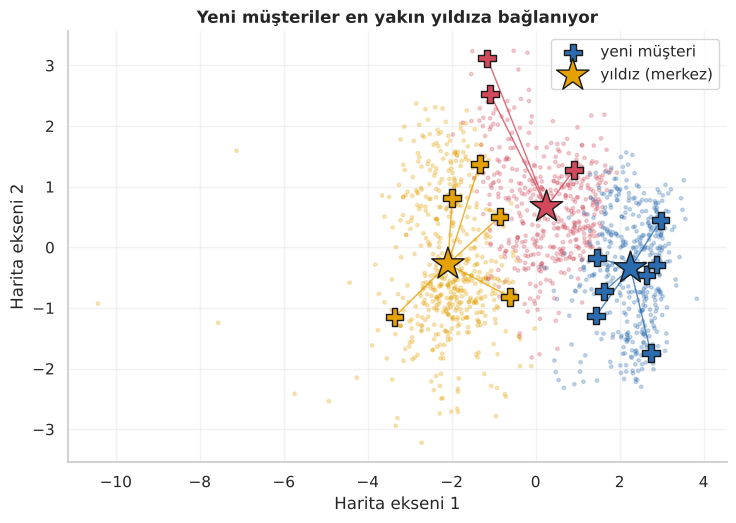

In [18]:
# Harita üzerinde: eğitim müşterileri (soluk), yeni gelen 15 test müşterisi (yıldız) ve en yakın merkezlerine çizgiler
p2 = PCA(2, random_state=RANDOM_STATE).fit(Ztr)
Htr, Hte, Hc = p2.transform(Ztr), p2.transform(Zte), p2.transform(km.cluster_centers_)
fig, ax = plt.subplots(figsize=(8.5, 5.6))
ax.scatter(Htr[:, 0], Htr[:, 1], s=6, c=[KUME_RENK[e] for e in km.labels_], alpha=.25)
yeni = np.arange(15)
for i in yeni:
    ax.plot([Hte[i, 0], Hc[et_te[i], 0]], [Hte[i, 1], Hc[et_te[i], 1]], color=KUME_RENK[et_te[i]], lw=1, alpha=.8)
ax.scatter(Hte[yeni, 0], Hte[yeni, 1], s=160, marker="P", c=[KUME_RENK[e] for e in et_te[yeni]], edgecolor="k", zorder=4, label="yeni müşteri")
ax.scatter(Hc[:, 0], Hc[:, 1], s=600, marker="*", c=KUME_RENK[:3], edgecolor="k", zorder=5, label="yıldız (merkez)")
ax.set(title="Yeni müşteriler en yakın yıldıza bağlanıyor", xlabel="Harita ekseni 1", ylabel="Harita ekseni 2"); ax.legend()
kaydet(fig, "kavram_11_yeni_musteri"); plt.show()

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

`predict()` büyülü bir şey yapmıyor: yeni müşteriyi **en yakın yıldıza** bağlıyor. Test silüetinin eğitime yakın çıkması, bulunan grupların **yalnızca eğitim verisine özgü olmadığını**, yeni müşterilerde de benzer biçimde var olduğunu gösterir. Grup paylarının eğitim ve testte benzer olması da iyi bir işarettir.

</td></tr></table>

<a id="p12"></a>

<p align="center">
  <img src="assets/kavram_12.svg" width="100%" alt="Bölüm 12: Özet">
</p>


### 🧠 Akılda Kalacaklar

<table>
<tr><td width="33%" valign="top" align="center"><h3>🏷️</h3><b>Gözetimsiz öğrenme</b><br><sub><i>etiket yok</i></sub><br><br>Cevap anahtarı olmadan <b>benzerleri gruplar</b>; kaliteyi farklı ölçütlerle ölçeriz<br><br></td><td width="33%" valign="top" align="center"><h3>🔁</h3><b>İki adım</b><br><sub><i>ata → taşı</i></sub><br><br>En yakın yıldıza ata, yıldızı ortalamaya taşı; WCSS hiç artmaz, algoritma durur<br><br></td><td width="33%" valign="top" align="center"><h3>➗</h3><b>Önce ölçekle</b><br><sub><i>StandardScaler / MinMaxScaler</i></sub><br><br>Ölçeksiz veride büyük sayılı özellik <b>tek başına</b> karar verir<br><br></td></tr>
<tr><td width="33%" valign="top" align="center"><h3>🎲</h3><b>Başlangıç önemli</b><br><sub><i>K-Means++ · n_init</i></sub><br><br>Dağınık başlat, birkaç kez dene, en küçük WCSS'i tut<br><br></td><td width="33%" valign="top" align="center"><h3>🦵</h3><b>Kaç küme?</b><br><sub><i>dirsek + 3 ölçüt + iş</i></sub><br><br>Ölçütler <b>aday</b> verir; kararı kararlılık ve iş anlamı birlikte verir<br><br></td><td width="33%" valign="top" align="center"><h3>🌙</h3><b>Sınırlar</b><br><sub><i>yuvarlak varsayımı</i></sub><br><br>Hilal, halka, eğik ve farklı yoğunluklu gruplarda <b>kardeş algoritmalar</b> denenmeli<br><br></td></tr>
</table>

### ❓ Quiz (cevaplar açılır kutularda)

<details><summary><b>1.</b> K-Means neden "gözetimsiz" bir algoritmadır?</summary>

Eğitim sırasında **hiçbir etiket (cevap) kullanmaz**. Yalnızca özelliklere bakarak birbirine benzeyen noktaları gruplar; grupların adını ve anlamını sonradan biz veririz.
</details>

<details><summary><b>2.</b> K-Means'in iki temel adımı nedir ve ne zaman durur?</summary>

**Ata:** her nokta en yakın merkeze bağlanır. **Taşı:** her merkez, kendine bağlanan noktaların ortalamasına gider. Hiçbir nokta grup değiştirmediğinde (merkezler kımıldamadığında) ya da en fazla tur sayısına ulaşıldığında durur.
</details>

<details><summary><b>3.</b> WCSS neden k arttıkça hep azalır, bu yüzden "en küçük WCSS'i seç" neden yanlış olur?</summary>

Daha fazla merkez, her noktanın bir merkeze daha yakın olması demektir; k = nokta sayısı olduğunda WCSS sıfırdır. En küçük WCSS her zaman en büyük k'yı seçtirir; bu yüzden **düşüşün yavaşladığı** dirsek noktasına bakarız.
</details>

<details><summary><b>4.</b> Silüet değeri −0,2 olan bir müşteri ne anlatır?</summary>

Bu müşteri **komşu gruba**, kendi grubundan daha yakın: muhtemelen yanlış gruba düşmüş ya da iki grubun sınırında. Negatif silüetli müşterilerin oranı, kümelemenin kalitesi hakkında bir uyarıdır.
</details>

<details><summary><b>5.</b> Ölçekleyiciyi tüm veride öğrenip sonra eğitim/test diye bölmek neden yanlıştır?</summary>

Ortalama ve yayılım **test müşterilerini de görerek** hesaplanır; test bilgisi eğitime sızar ve test skoru iyimser çıkar. Doğrusu: ölçekleyiciyi **yalnızca eğitimde** öğrenmek, teste yalnızca uygulamak (ya da her şeyi bir `Pipeline` içine koymak).
</details>

### 🏠 Ödevler

1. 3.2'deki animasyonu **iyi bir başlangıçla** (`init="k-means++"`) tekrar üretin; kaç turda duruyor?
2. 6.1'deki deneyi `StandardScaler` yerine **`MinMaxScaler`** ile tekrarlayın; çocuk sayısının η²'si nasıl değişiyor?
3. 7.2'deki sentetik veride `cluster_std` değerini 0,6'dan 1,5'e çıkarın: başlangıç tuzağı **büyüyor mu, küçülüyor mu**? Neden?
4. 9.2'deki tabloyu yalnızca **3 özellikle** (Gelir, Toplam harcama, Çocuk) tekrar hesaplayın; en iyi k değişiyor mu?
5. *(Zor)* 10.1'deki "Hilal" verisinde DBSCAN'in `eps` değerini 0,1'den 0,6'ya kadar tarayın ve ARI'nin `eps` ile nasıl değiştiğini çizin.

### 📚 KAYNAKÇA

Metin içi atıflar APA 7 biçimindedir. **Dolaylı atıf**, kaynağa ikinci elden ulaşıldığında "(B, A'dan aktarma)" kalıbıyla gösterilir. Bu notebook'ta örnekler: *K-Means fikrinin kökleri Steinhaus'un (1956) çalışmasına uzanır (Steinhaus, 1956; Jain, 2010'dan aktarma); algoritmaya "k-means" adı MacQueen (1967) tarafından verilmiştir (MacQueen, 1967; Ikotun ve ark., 2023'ten aktarma).* Dirsek fikrinin erken bir örneği Thorndike'tır (1953). Başlangıç tuzağı ve çözümü için Arthur ve Vassilvitskii (2007), dirsek noktasının otomatik bulunması için Satopää ve ark. (2011), kalite ölçütleri için Rousseeuw (1987), Davies ve Bouldin (1979) ile Caliński ve Harabasz (1974) esas alınmıştır. Güncel derleme olarak Ikotun ve ark. (2023) kullanılmıştır. *Not: Steinhaus (1956) ve MacQueen (1967) çalışmalarının tam metnine bu çalışma ortamından ulaşılamadı; bu yüzden dolaylı atıf kullanıldı. Diğer künyeler yayıncı/özet sayfalarından doğrulanmıştır.*

- Arthur, D., & Vassilvitskii, S. (2007). k-means++: The advantages of careful seeding. In *Proceedings of the Eighteenth Annual ACM-SIAM Symposium on Discrete Algorithms* (pp. 1027–1035). Society for Industrial and Applied Mathematics.
- Caliński, T., & Harabasz, J. (1974). A dendrite method for cluster analysis. *Communications in Statistics, 3*(1), 1–27. https://doi.org/10.1080/03610927408827101
- Davies, D. L., & Bouldin, D. W. (1979). A cluster separation measure. *IEEE Transactions on Pattern Analysis and Machine Intelligence, PAMI-1*(2), 224–227. https://doi.org/10.1109/TPAMI.1979.4766909
- Ester, M., Kriegel, H.-P., Sander, J., & Xu, X. (1996). A density-based algorithm for discovering clusters in large spatial databases with noise. In *Proceedings of the Second International Conference on Knowledge Discovery and Data Mining* (pp. 226–231). AAAI Press.
- Hubert, L., & Arabie, P. (1985). Comparing partitions. *Journal of Classification, 2*(1), 193–218. https://doi.org/10.1007/BF01908075
- Ikotun, A. M., Ezugwu, A. E., Abualigah, L., Abuhaija, B., & Heming, J. (2023). K-means clustering algorithms: A comprehensive review, variants analysis, and advances in the era of big data. *Information Sciences, 622*, 178–210. https://doi.org/10.1016/j.ins.2022.11.139
- Jain, A. K. (2010). Data clustering: 50 years beyond K-means. *Pattern Recognition Letters, 31*(8), 651–666. https://doi.org/10.1016/j.patrec.2009.09.011
- Lloyd, S. P. (1982). Least squares quantization in PCM. *IEEE Transactions on Information Theory, 28*(2), 129–137. https://doi.org/10.1109/TIT.1982.1056489
- MacQueen, J. (1967). Some methods for classification and analysis of multivariate observations. In L. M. Le Cam & J. Neyman (Eds.), *Proceedings of the Fifth Berkeley Symposium on Mathematical Statistics and Probability* (Vol. 1, pp. 281–297). University of California Press.
- Patel, A. (2021). *Customer personality analysis* [Data set]. Kaggle. https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., … Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53–65. https://doi.org/10.1016/0377-0427(87)90125-7
- Satopää, V., Albrecht, J., Irwin, D., & Raghavan, B. (2011). Finding a "kneedle" in a haystack: Detecting knee points in system behavior. In *2011 31st International Conference on Distributed Computing Systems Workshops* (pp. 166–171). IEEE. https://doi.org/10.1109/ICDCSW.2011.20
- Steinhaus, H. (1956). Sur la division des corps matériels en parties. *Bulletin de l'Académie Polonaise des Sciences, Classe III, 4*(12), 801–804.
- Thorndike, R. L. (1953). Who belongs in the family? *Psychometrika, 18*(4), 267–276. https://doi.org/10.1007/BF02289263

<p align="center">
  <img src="assets/kapanis_kavram.svg" width="100%" alt="Kapanış">
</p>